In [7]:
# ============================================================
# DATA QUALITY & CLEANING PROJECT
# Dataset: LendingClub Rejected 50K
# Jupyter Notebook - ONE CELL VERSION (portable paths)
# Objective: Diagnose, visualize, clean, document and validate
# IMPORTANT: Original/raw files are NEVER modified.
# ============================================================

# 1. IMPORT LIBRARIES
import os
import re
import warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

# ============================================================
# 2. USER SETTINGS  <-- EDIT ONLY THIS BLOCK
# ============================================================
# All paths below are RELATIVE to the project folder, so the
# code works on any device without changes.

REPO_FOLDER_NAME    = "DEPI-ITC-ONL5-DA-Team3-G3-Projects"   # repo (git clone) folder
PROJECT_FOLDER_NAME = "FinalProject"                         # folder holding all the work

# Optional: set a full path ONLY if auto-detection fails on some machine.
# Leave as None normally.   Example: PROJECT_DIR_OVERRIDE = r"D:\my\FinalProject"
PROJECT_DIR_OVERRIDE = None

# --- INPUT: which file to pick, and where it lives ---
INPUT_SUBDIR    = Path("data") / "Sampled"
INPUT_FILE_NAME = "sample_rejected_2007_to_2018Q4.csv"

# --- OUTPUT: where to write results (REJECTED-specific) ---
CLEANED_SUBDIR    = Path("data") / "Cleaned" / "Sample"
CLEANED_FILE_NAME = "rejected_cleaned.csv"  # Main row-filtered dataset

REPORT_SUBDIR       = Path("docs") / "Data Cleaning" / "Sample"
DATASET_REPORT_NAME = "Rejected"                      # sub-folder inside the report folder
GUIDE_FILE_NAME     = "Rejected_Cleaning_Guide.md"

# Small yearly groups will be marked as low-volume.
MIN_ROWS_PER_YEAR = 30

# ============================================================
# 3. RESOLVE PROJECT ROOT AUTOMATICALLY
# ============================================================

def find_project_dir(project_name, repo_name, override=None):
    """
    Finds the project folder no matter where the notebook is running from:
      - inside FinalProject (or any sub-folder of it)
      - at the repo root
      - in a folder next to / above the repo
    """
    if override:
        p = Path(override).expanduser().resolve()
        if not p.is_dir():
            raise FileNotFoundError(f"PROJECT_DIR_OVERRIDE does not exist: {p}")
        return p

    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        # case 1: we are inside FinalProject
        if p.name == project_name:
            return p
        # case 2: FinalProject is a direct child (e.g. we are at the repo root)
        if (p / project_name).is_dir():
            return p / project_name
        # case 3: repo folder is a child of this folder
        if (p / repo_name / project_name).is_dir():
            return p / repo_name / project_name

    raise FileNotFoundError(
        f"Could not find a '{project_name}' folder starting from: {start}\n"
        f"Open the notebook inside the '{repo_name}' repo, "
        "or set PROJECT_DIR_OVERRIDE in the settings block."
    )

PROJECT_DIR = find_project_dir(PROJECT_FOLDER_NAME, REPO_FOLDER_NAME, PROJECT_DIR_OVERRIDE)

# ============================================================
# 3.1 BUILD ALL PATHS FROM THE SETTINGS
# ============================================================

INPUT_DIR   = PROJECT_DIR / INPUT_SUBDIR
CLEANED_DIR = PROJECT_DIR / CLEANED_SUBDIR
REPORT_ROOT = PROJECT_DIR / REPORT_SUBDIR

# Dedicated rejected-loans folders (separate from Accepted)
DATASET_REPORT_DIR = REPORT_ROOT / DATASET_REPORT_NAME
BEFORE_DIR  = DATASET_REPORT_DIR / "Before_Cleaning"
AFTER_DIR   = DATASET_REPORT_DIR / "After_Cleaning"
REPORT_DIR  = DATASET_REPORT_DIR
OUTPUT_ROOT = DATASET_REPORT_DIR   # kept for compatibility with the old rejected code

FILE_PATH    = INPUT_DIR / INPUT_FILE_NAME
CLEANED_FILE = CLEANED_DIR / CLEANED_FILE_NAME
GUIDE_FILE   = REPORT_ROOT / GUIDE_FILE_NAME

# Same dict structure as the old rejected notebook, so later cells still work
INPUT_FILES = {"50K_Sample": FILE_PATH}

for folder in [CLEANED_DIR, REPORT_ROOT, DATASET_REPORT_DIR, BEFORE_DIR, AFTER_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Convert to plain strings so any later code using os.path / string
# concatenation keeps working exactly as before.
(PROJECT_DIR, INPUT_DIR, CLEANED_DIR, REPORT_ROOT, DATASET_REPORT_DIR,
 BEFORE_DIR, AFTER_DIR, REPORT_DIR, OUTPUT_ROOT, FILE_PATH, CLEANED_FILE, GUIDE_FILE) = map(
    str,
    (PROJECT_DIR, INPUT_DIR, CLEANED_DIR, REPORT_ROOT, DATASET_REPORT_DIR,
     BEFORE_DIR, AFTER_DIR, REPORT_DIR, OUTPUT_ROOT, FILE_PATH, CLEANED_FILE, GUIDE_FILE),
)
INPUT_FILES = {k: str(v) for k, v in INPUT_FILES.items()}

print("Project root :", PROJECT_DIR)
print("Input file   :", FILE_PATH)
print("Cleaned file :", CLEANED_FILE)
print("Reports dir  :", REPORT_DIR)

# ============================================================
# 3.2 LOAD RAW DATA
# ============================================================

def load_data(file_path):
    if not os.path.exists(file_path):
        available = (
            sorted(p.name for p in Path(file_path).parent.glob("*.csv"))
            if Path(file_path).parent.exists() else []
        )
        raise FileNotFoundError(
            f"File not found: {file_path}\n"
            f"CSV files found in that folder: {available if available else 'none'}\n"
            "Fix INPUT_SUBDIR / INPUT_FILE_NAME in the settings block."
        )

    try:
        return pd.read_csv(file_path, low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(file_path, encoding="cp1252", low_memory=False)

raw_df = load_data(FILE_PATH)
df = raw_df.copy(deep=True)

print("\nDATA LOADED SUCCESSFULLY")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

try:
    display(df.head())      # Jupyter
except NameError:
    print(df.head())        # plain Python fallback

Project root : G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject
Input file   : G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\data\Sampled\sample_rejected_2007_to_2018Q4.csv
Cleaned file : G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\data\Cleaned\Sample\rejected_cleaned.csv
Reports dir  : G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\docs\Data Cleaning\Sample\Rejected

DATA LOADED SUCCESSFULLY
Rows: 50000
Columns: 9


,Amount Requested,Application Date,Loan Title,Risk_Score,Debt-To-Income Ratio,Zip Code,State,Employment Length,Policy Code
0,1600.0,2007-08-02,smochan,427.0,15.74%,150xx,OH,1 year,0.0
1,500.0,2007-09-25,imbeautiful1,395.0,17.91%,701xx,LA,3 years,0.0
2,800.0,2007-10-06,Turtle,0.0,0%,024xx,MA,< 1 year,0.0
3,1500.0,2007-11-27,other,662.0,3.08%,276xx,NC,< 1 year,0.0
4,23000.0,2007-12-13,cjbk,621.0,2.21%,573xx,SD,1 year,0.0


In [8]:

# ============================================================
# CELL 2 - HELPER FUNCTIONS
# ============================================================

def save_plot(filename):
    """Save the current plot."""
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()


def add_log(log_list, stage, column, issue, action, rows=0, details=""):
    log_list.append({
        "Stage": stage,
        "Column": column,
        "Issue": issue,
        "Action": action,
        "Affected_Rows": int(rows),
        "Details": details
    })


def parse_dti(series):
    """Convert DTI percentage strings to numeric values."""
    cleaned = (
        series.astype("string")
        .str.strip()
        .str.replace("%", "", regex=False)
        .str.replace(",", "", regex=False)
    )
    return pd.to_numeric(cleaned, errors="coerce")


def clean_text(series):
    """Remove leading/trailing and repeated whitespace."""
    return (
        series.astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .replace("", pd.NA)
    )


def calculate_iqr_bounds(series, multiplier=1.5):
    """Return Q1, Q3, IQR and IQR bounds for numeric non-null values."""
    numeric = pd.to_numeric(series, errors="coerce")
    valid = numeric.dropna()

    if len(valid) < 4:
        return {
            "Q1": np.nan, "Q3": np.nan, "IQR": np.nan,
            "Lower_Bound": np.nan, "Upper_Bound": np.nan,
            "Valid_Count": int(len(valid)),
            "Method": f"IQR ({multiplier} x IQR); insufficient observations"
        }

    q1 = float(valid.quantile(0.25))
    q3 = float(valid.quantile(0.75))
    iqr = q3 - q1
    lower = q1 - multiplier * iqr
    upper = q3 + multiplier * iqr

    return {
        "Q1": q1, "Q3": q3, "IQR": float(iqr),
        "Lower_Bound": float(lower), "Upper_Bound": float(upper),
        "Valid_Count": int(len(valid)),
        "Method": f"Upper outlier if value > Q3 + {multiplier} x IQR"
    }


def detect_iqr_outliers(series):
    """Return two-sided IQR outlier flags without changing the values."""
    numeric = pd.to_numeric(series, errors="coerce")
    bounds = calculate_iqr_bounds(numeric)
    if pd.isna(bounds["Lower_Bound"]) or pd.isna(bounds["Upper_Bound"]):
        return pd.Series(False, index=series.index)
    return (numeric < bounds["Lower_Bound"]) | (numeric > bounds["Upper_Bound"])


def detect_category_variants(series):
    """
    Detect different raw labels that become identical
    after lowercase + whitespace normalization.
    """
    values = series.dropna().astype(str)

    if values.empty:
        return pd.DataFrame(
            columns=["Normalized_Value", "Original_Variants", "Variant_Count"]
        )

    temp = pd.DataFrame({"Original": values})
    temp["Normalized"] = (
        temp["Original"]
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    grouped = (
        temp.groupby("Normalized")["Original"]
        .agg(lambda x: sorted(set(x)))
        .reset_index()
    )

    grouped["Variant_Count"] = grouped["Original"].apply(len)

    result = grouped[grouped["Variant_Count"] > 1].copy()

    result = result.rename(columns={
        "Normalized": "Normalized_Value",
        "Original": "Original_Variants"
    })

    return result




PROCESSING: 50K_Sample
Rows: 50000
Columns: 9


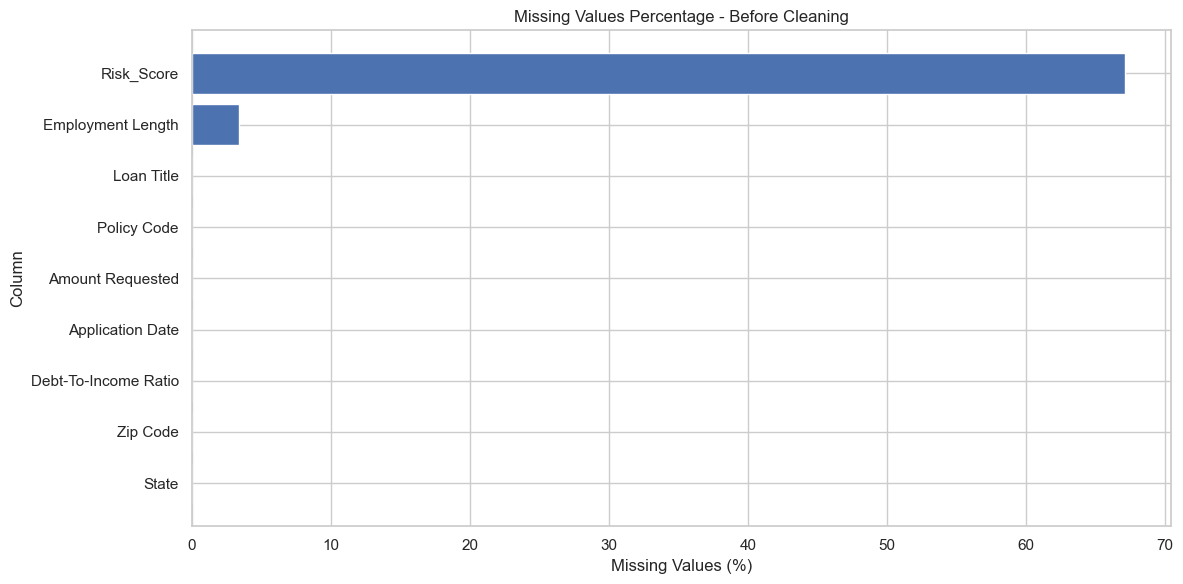

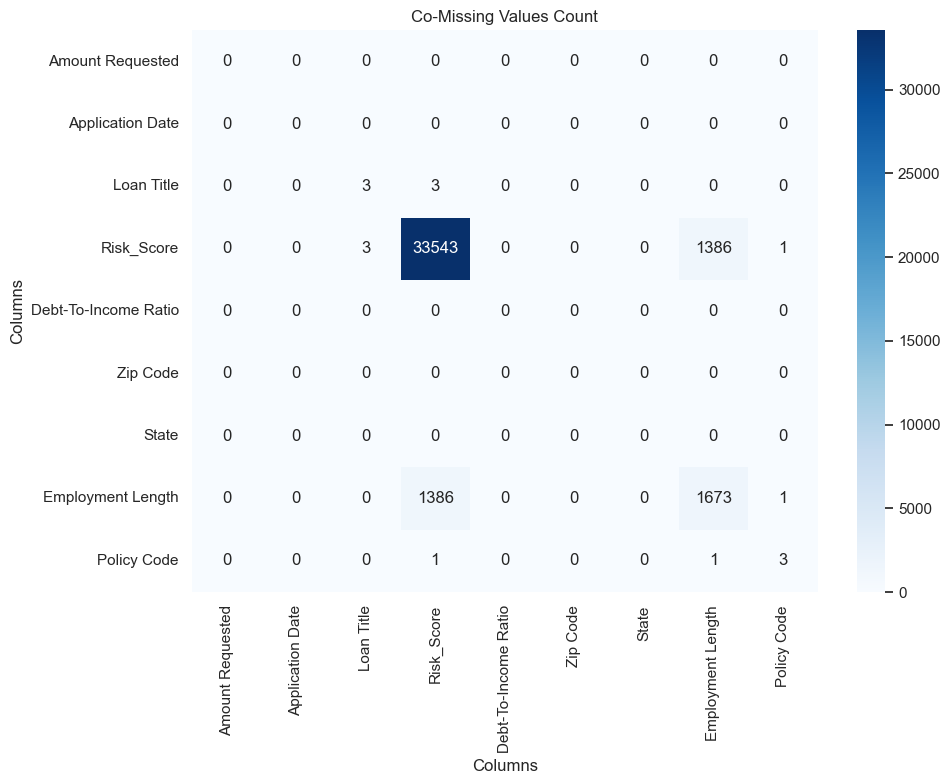

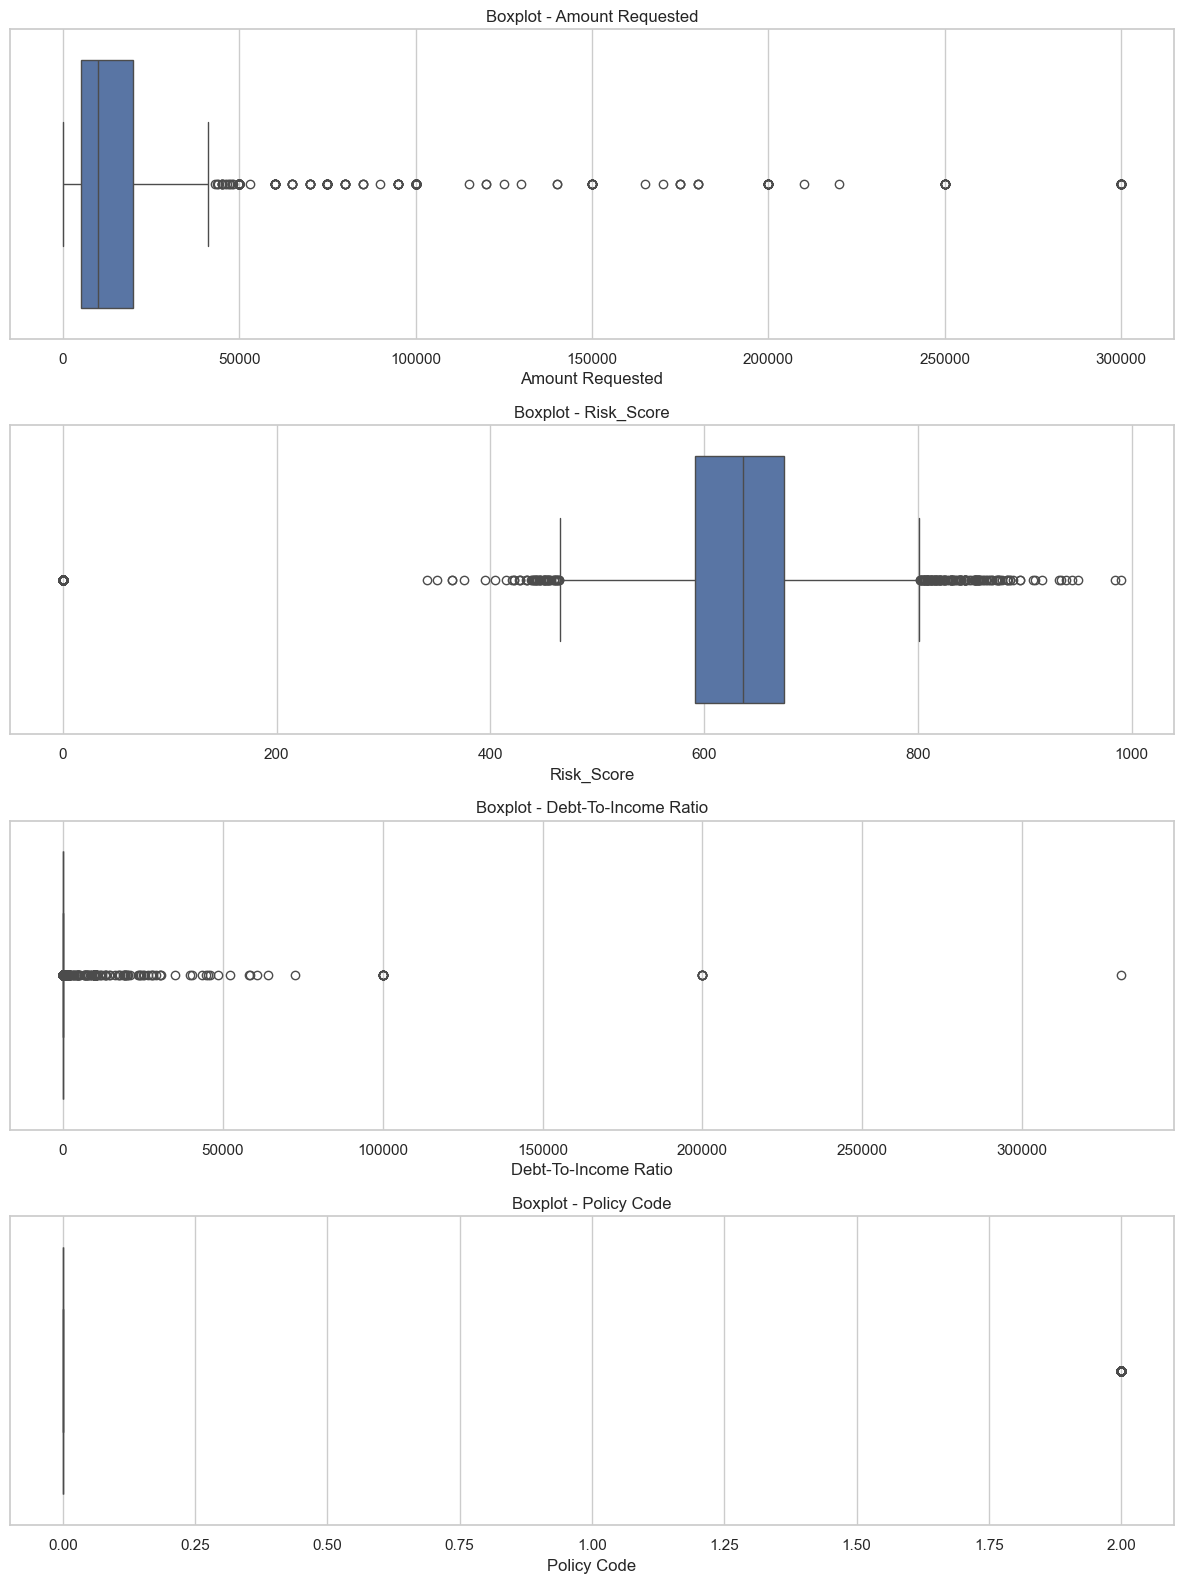

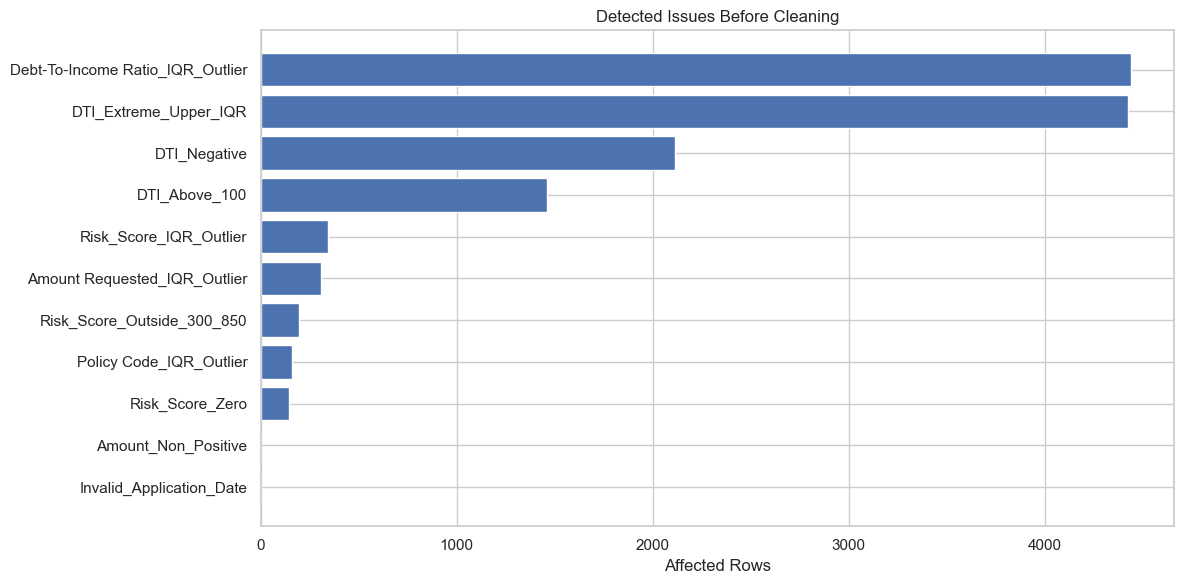

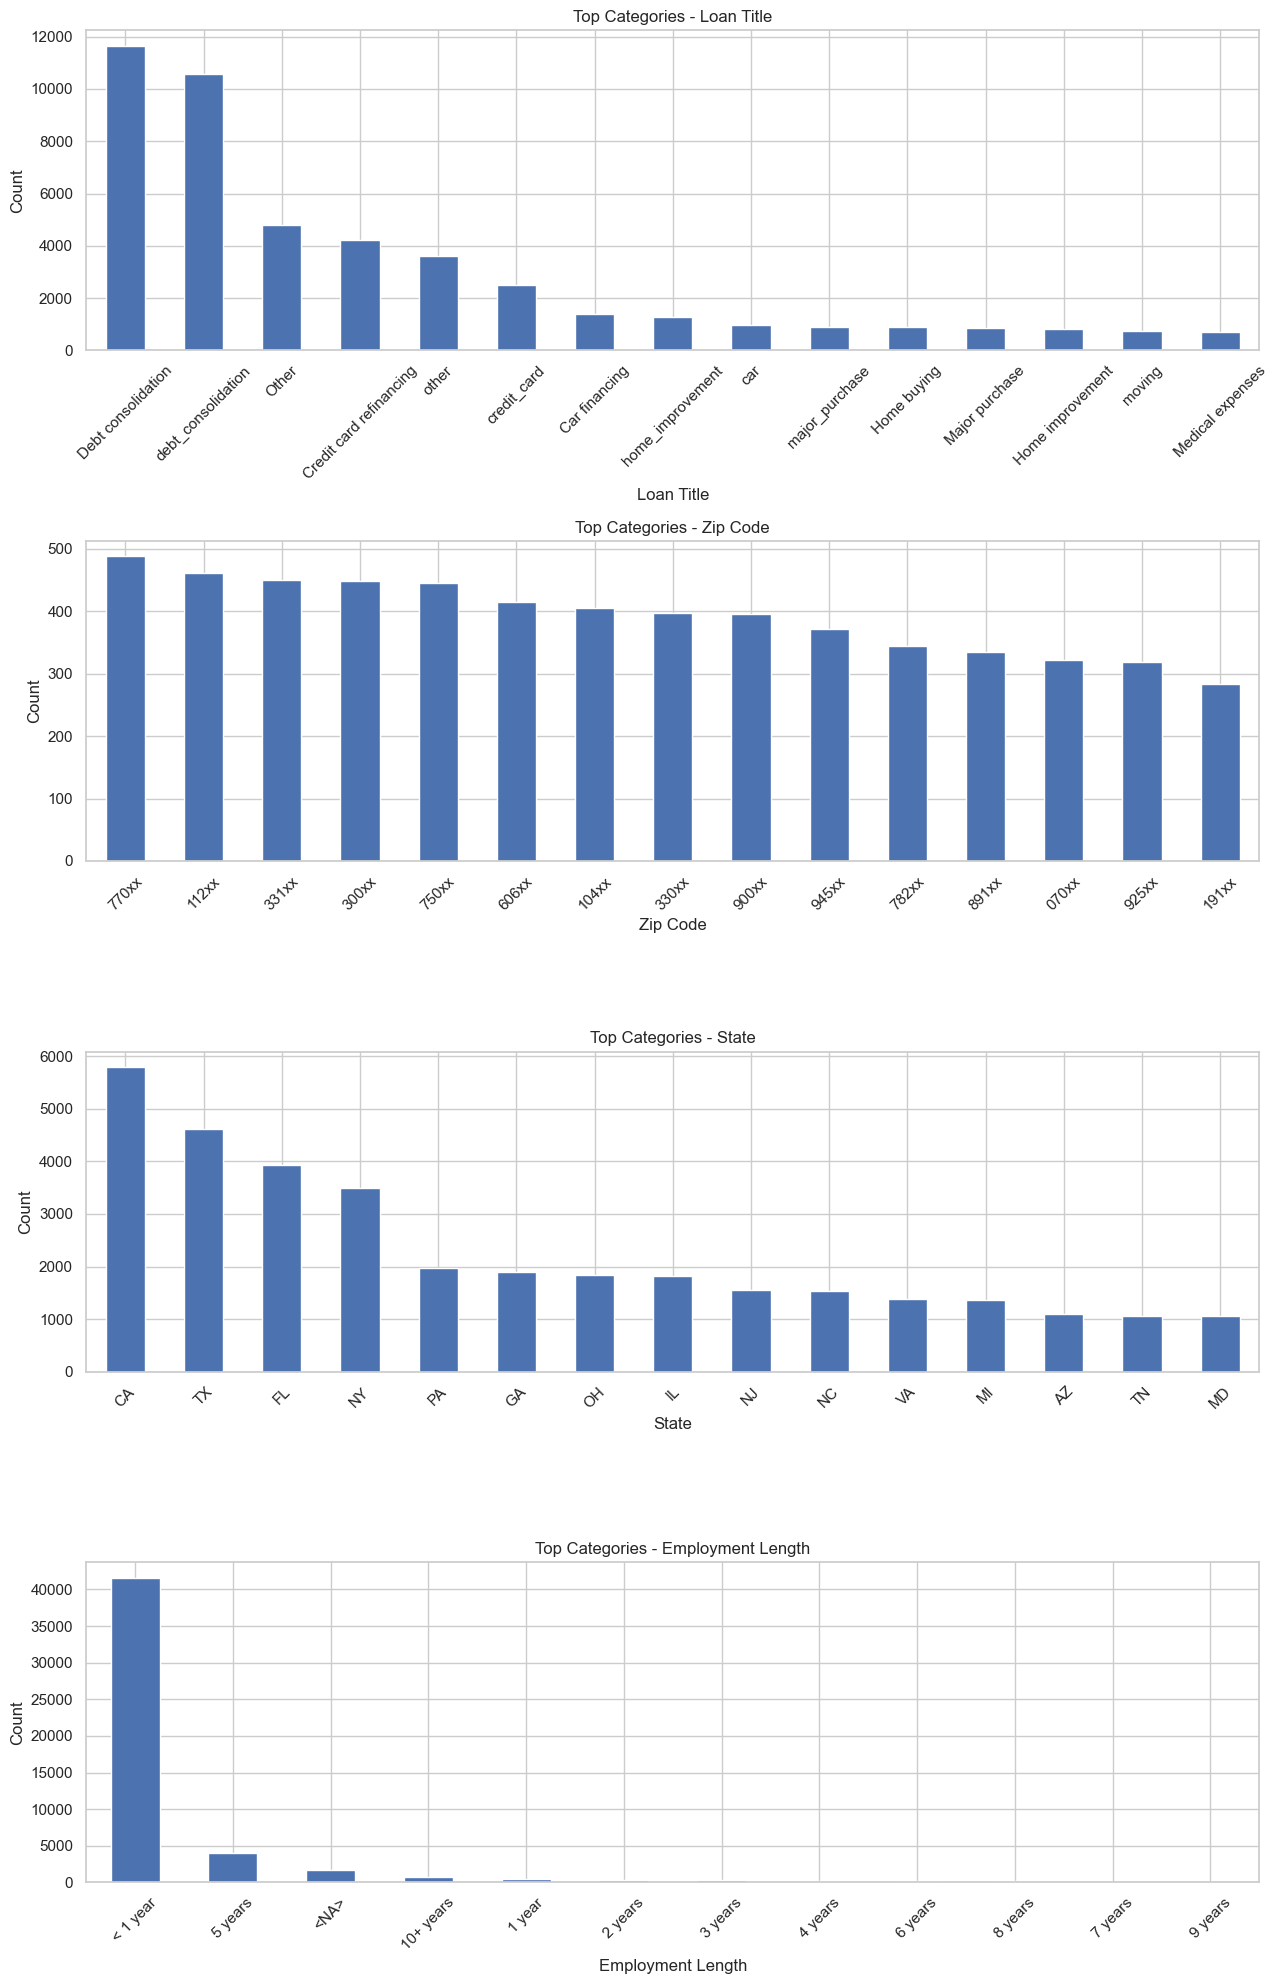

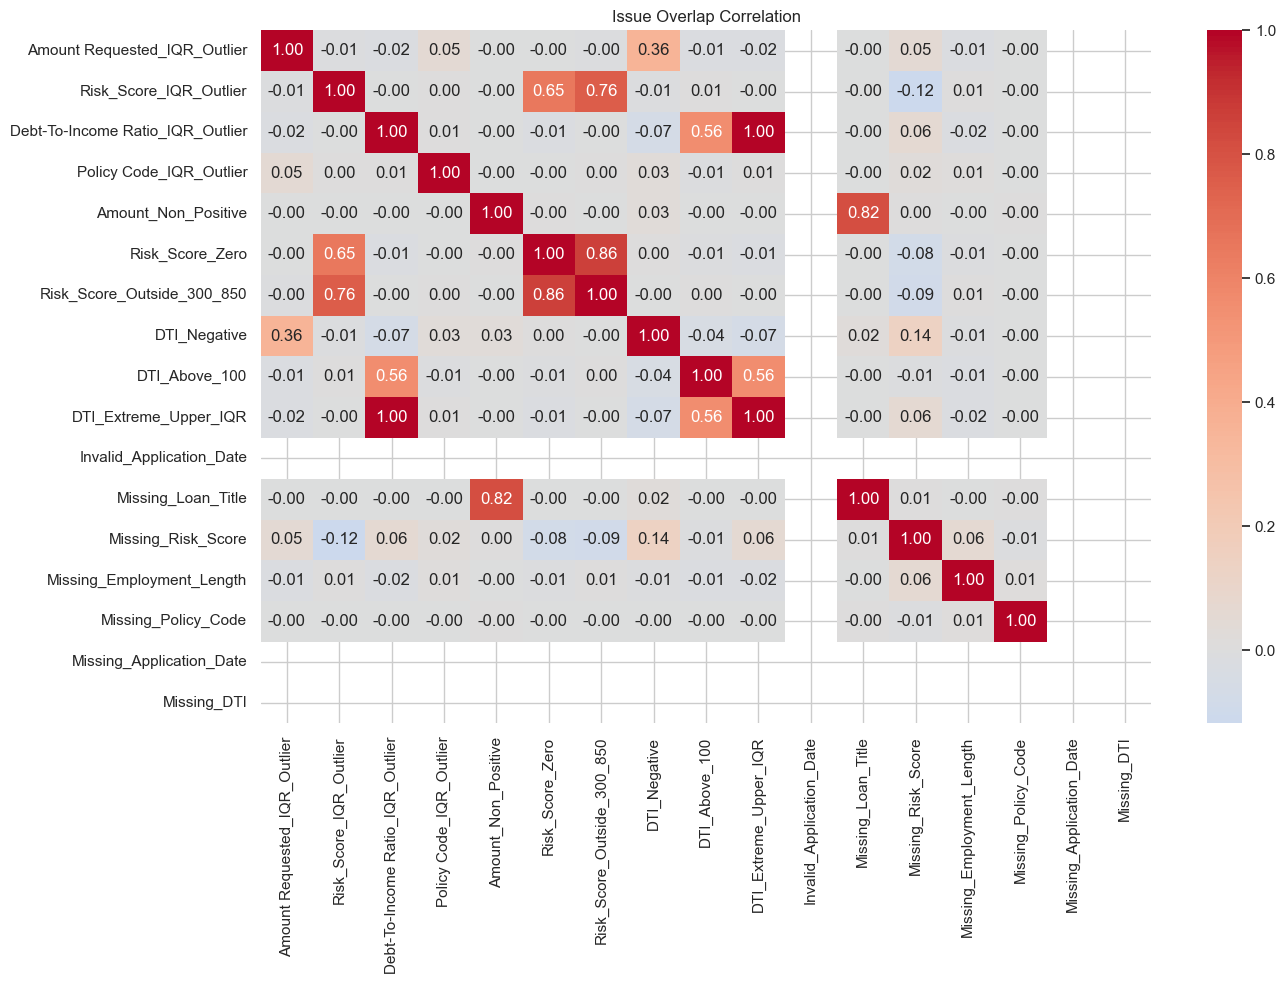

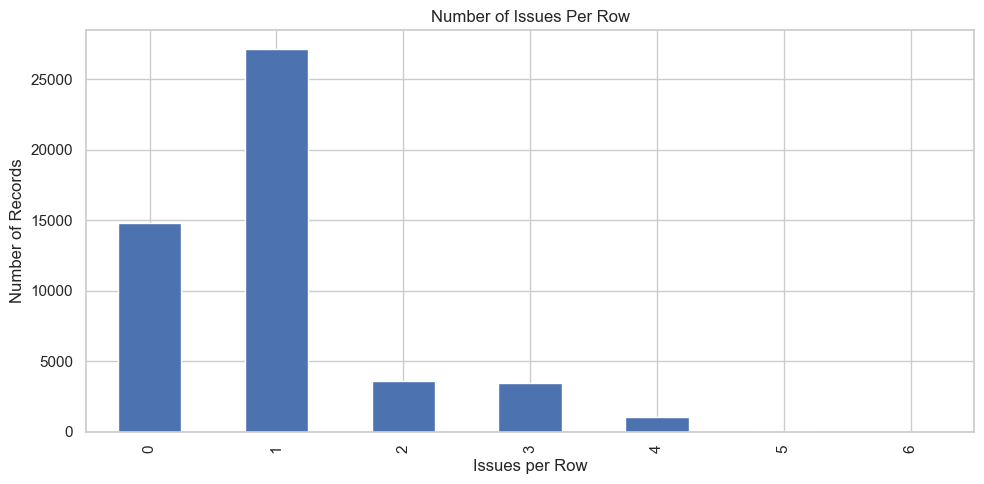

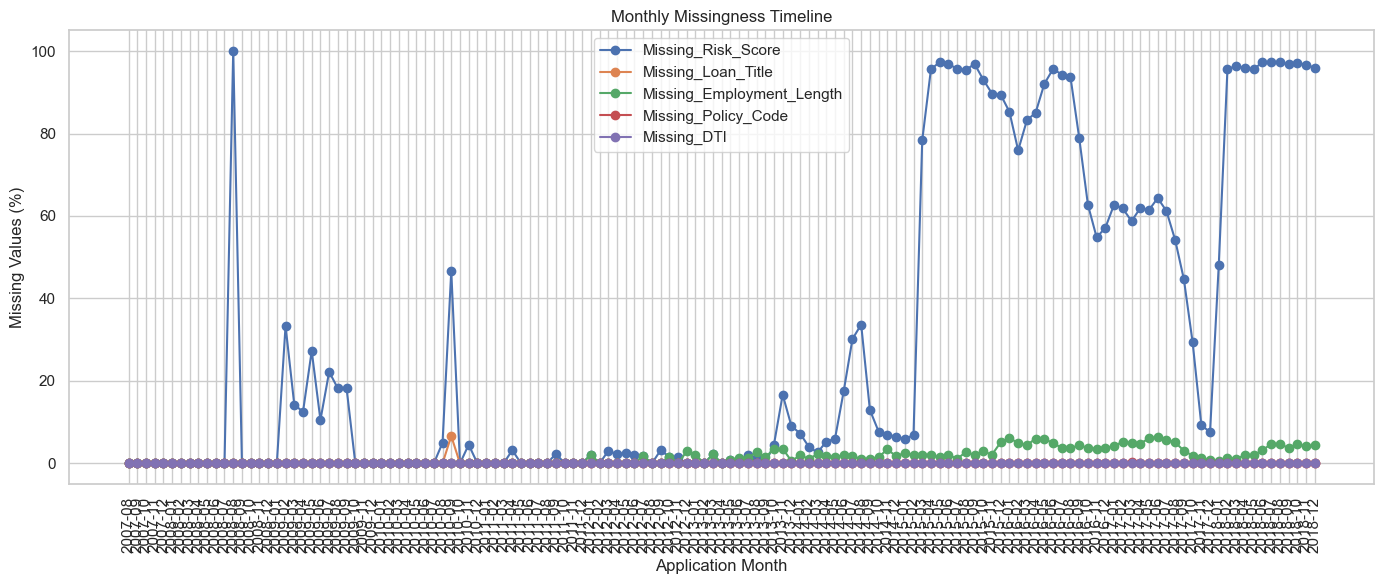

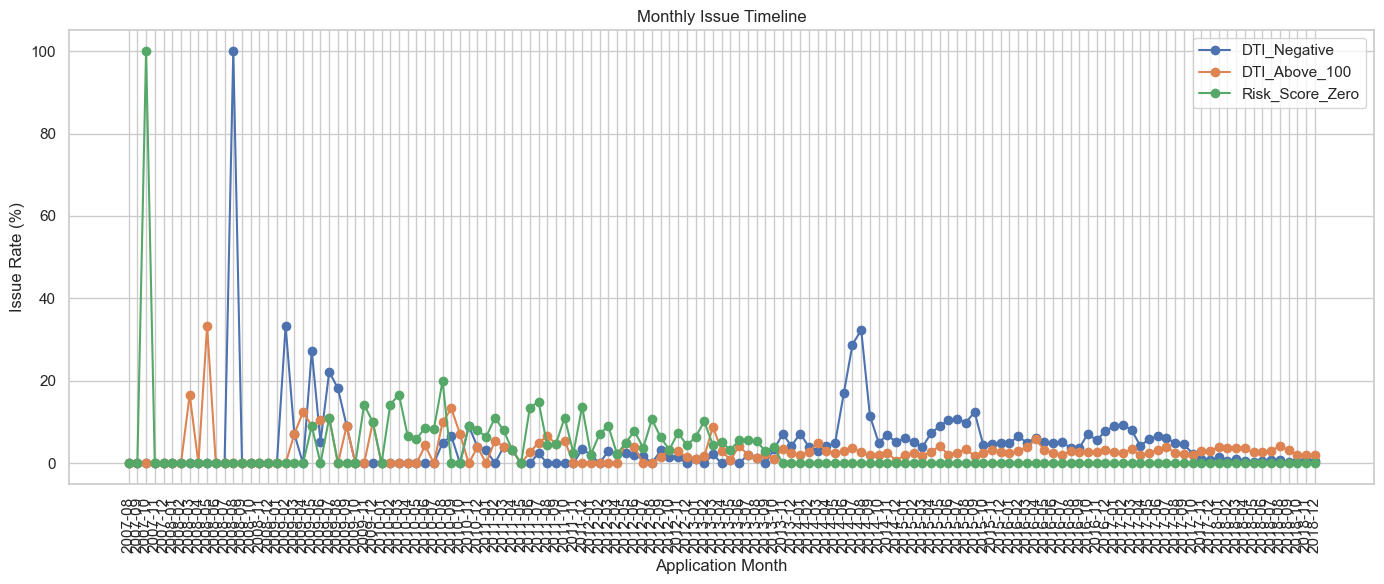


PIPELINE COMPLETED
Dataset: 50K_Sample
Original shape: (50000, 9)
Flagged dataset shape: (50000, 18)
Main cleaned dataset shape: (15115, 8)
Extreme DTI dataset shape: (1012, 8)
DTI IQR upper bound: 79.695
Flagged CSV: G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\data\Cleaned\Sample\rejected_flagged.csv
Main cleaned CSV: G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\data\Cleaned\Sample\rejected_cleaned.csv
Extreme DTI CSV: G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\data\Cleaned\Sample\rejected_extreme_dti.csv
Cleaning guide: G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\docs\Data Cleaning\Sample\Rejected\Reports\Rejected_Cleaning_Guide.md
Raw file modified: NO
Documentation folder: G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\docs\Data Cleaning\Sample\Rejected

ALL AVAILABLE DATASETS PROCESSED.


In [9]:

# ============================================================
# CELL 3 - PROCESS EACH DATASET
# ============================================================

def run_data_quality_pipeline(dataset_name, input_path):

    print("\n" + "=" * 70)
    print("PROCESSING:", dataset_name)
    print("=" * 70)

    if not os.path.exists(input_path):
        print("File not found:", input_path)
        return

    # The 50K sample uses the designated Rejected folder directly.
    # Other future datasets can retain their own subfolder.
    output_dir = (
        REPORT_DIR if dataset_name == "50K_Sample"
        else os.path.join(REPORT_DIR, dataset_name)
    )
    charts_dir = os.path.join(output_dir, "Before_Cleaning")
    after_dir = os.path.join(output_dir, "After_Cleaning")
    diagnostic_tables_dir = os.path.join(output_dir, "Diagnostic_Tables")
    reports_dir = os.path.join(output_dir, "Reports")

    os.makedirs(charts_dir, exist_ok=True)
    os.makedirs(after_dir, exist_ok=True)
    os.makedirs(diagnostic_tables_dir, exist_ok=True)
    os.makedirs(reports_dir, exist_ok=True)

    # Read the raw file. Never overwrite it.
    raw = pd.read_csv(input_path, low_memory=False)

    # Preserve an independent copy for comparison.
    df = raw.copy(deep=True)

    print("Rows:", len(raw))
    print("Columns:", len(raw.columns))

    # Keep a log for every diagnostic and transformation.
    cleaning_log = []

    # Normalize column names in the working copy only.
    original_columns = list(df.columns)

    df.columns = (
        df.columns.astype(str)
        .str.strip()
    )

    if list(df.columns) != original_columns:
        add_log(
            cleaning_log,
            "Preparation",
            "Column Names",
            "Whitespace in column names",
            "Trimmed column names in working copy",
            len(df),
            "Raw file was not changed."
        )

    # --------------------------------------------------------
    # CELL 4 - DIAGNOSTIC DATA PREPARATION
    # This section creates diagnostic copies only.
    # No cleaning is performed here.
    # --------------------------------------------------------

    required_columns = [
        "Amount Requested",
        "Application Date",
        "Loan Title",
        "Risk_Score",
        "Debt-To-Income Ratio",
        "Zip Code",
        "State",
        "Employment Length",
        "Policy Code"
    ]

    missing_columns = [
        c for c in required_columns if c not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing expected columns: {missing_columns}"
        )

    # Parse diagnostic dates without changing the original column.
    diagnostic_date = pd.to_datetime(
        df["Application Date"],
        errors="coerce"
    )

    # Parse DTI in a separate diagnostic series.
    diagnostic_dti = parse_dti(df["Debt-To-Income Ratio"])

    diagnostic_numeric = {
        "Amount Requested": pd.to_numeric(
            df["Amount Requested"], errors="coerce"
        ),
        "Risk_Score": pd.to_numeric(
            df["Risk_Score"], errors="coerce"
        ),
        "Debt-To-Income Ratio": diagnostic_dti,
        "Policy Code": pd.to_numeric(
            df["Policy Code"], errors="coerce"
        )
    }

    # --------------------------------------------------------
    # CELL 5 - NULL ANALYSIS
    # --------------------------------------------------------

    null_report = pd.DataFrame({
        "Column": df.columns,
        "Missing_Count": df.isna().sum().values,
        "Missing_Percentage": (
            df.isna().mean().values * 100
        ).round(2)
    }).sort_values(
        "Missing_Percentage",
        ascending=False
    )

    null_report.to_csv(
        os.path.join(diagnostic_tables_dir, "Null_Analysis.csv"),
        index=False
    )

    # Graph 1: Missing values by column.
    plt.figure(figsize=(12, 6))

    ax = plt.gca()
    ax.barh(null_report["Column"], null_report["Missing_Percentage"])
    ax.invert_yaxis()

    plt.title("Missing Values Percentage - Before Cleaning")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Column")

    save_plot(
        os.path.join(charts_dir, "01_Missing_Values.png")
    )

    # Graph 2: Co-missing columns.
    # A value of 1 means both columns are missing in that row.
    missing_matrix = df.isna().astype(int)

    if len(df.columns) > 1:

        co_missing = missing_matrix.T.dot(missing_matrix)

        plt.figure(figsize=(10, 8))

        sns.heatmap(
            co_missing,
            annot=True,
            fmt="g",
            cmap="Blues"
        )

        plt.title("Co-Missing Values Count")
        plt.xlabel("Columns")
        plt.ylabel("Columns")

        save_plot(
            os.path.join(charts_dir, "02_Co_Missing_Heatmap.png")
        )

        co_missing.to_csv(
            os.path.join(diagnostic_tables_dir, "Co_Missing_Matrix.csv")
        )

    # --------------------------------------------------------
    # CELL 6 - OUTLIER ANALYSIS
    # --------------------------------------------------------

    outlier_flags = pd.DataFrame(index=df.index)

    for col, values in diagnostic_numeric.items():

        outlier_flags[col + "_IQR_Outlier"] = (
            detect_iqr_outliers(values)
        )

    # Additional domain-review flags.
    outlier_flags["Amount_Non_Positive"] = (
        diagnostic_numeric["Amount Requested"] <= 0
    )

    outlier_flags["Risk_Score_Zero"] = (
        diagnostic_numeric["Risk_Score"] == 0
    )

    outlier_flags["Risk_Score_Outside_300_850"] = (
        (diagnostic_numeric["Risk_Score"] < 300) |
        (diagnostic_numeric["Risk_Score"] > 850)
    )

    outlier_flags["DTI_Negative"] = diagnostic_dti < 0
    outlier_flags["DTI_Above_100"] = diagnostic_dti > 100

    diagnostic_valid_dti = diagnostic_dti[diagnostic_dti >= 0]
    diagnostic_dti_bounds = calculate_iqr_bounds(diagnostic_valid_dti)
    if pd.isna(diagnostic_dti_bounds["Upper_Bound"]):
        outlier_flags["DTI_Extreme_Upper_IQR"] = False
    else:
        outlier_flags["DTI_Extreme_Upper_IQR"] = (
            diagnostic_dti > diagnostic_dti_bounds["Upper_Bound"]
        )

    outlier_flags["Invalid_Application_Date"] = (
        diagnostic_date.isna()
    )

    outlier_flags.to_csv(
        os.path.join(diagnostic_tables_dir, "Outlier_And_Issue_Flags.csv"),
        index=False
    )

    outlier_summary = pd.DataFrame({
        "Issue": outlier_flags.columns,
        "Affected_Rows": outlier_flags.sum().values,
        "Percentage": (
            outlier_flags.mean().values * 100
        ).round(2)
    }).sort_values(
        "Affected_Rows",
        ascending=False
    )

    outlier_summary.to_csv(
        os.path.join(diagnostic_tables_dir, "Outlier_Summary.csv"),
        index=False
    )

    # Graph 3: Numeric distributions / boxplots.
    numeric_names = list(diagnostic_numeric.keys())

    fig, axes = plt.subplots(
        len(numeric_names),
        1,
        figsize=(12, 4 * len(numeric_names))
    )

    for ax, col in zip(axes, numeric_names):

        sns.boxplot(
            x=diagnostic_numeric[col],
            ax=ax
        )

        ax.set_title(f"Boxplot - {col}")

    save_plot(
        os.path.join(charts_dir, "03_Numeric_Outliers.png")
    )

    # Graph 4: Issue counts.
    plt.figure(figsize=(12, 6))

    ax = plt.gca()
    ax.barh(outlier_summary["Issue"], outlier_summary["Affected_Rows"])
    ax.invert_yaxis()

    plt.title("Detected Issues Before Cleaning")
    plt.xlabel("Affected Rows")

    save_plot(
        os.path.join(charts_dir, "04_Issue_Counts.png")
    )

    # --------------------------------------------------------
    # CELL 7 - INCONSISTENT CATEGORY ANALYSIS
    # --------------------------------------------------------

    category_columns = [
        "Loan Title",
        "Zip Code",
        "State",
        "Employment Length"
    ]

    category_reports = []

    for col in category_columns:

        variants = detect_category_variants(df[col])

        if not variants.empty:

            variants.insert(0, "Column", col)

            category_reports.append(variants)

    if category_reports:

        category_report = pd.concat(
            category_reports,
            ignore_index=True
        )

    else:

        category_report = pd.DataFrame(
            columns=[
                "Column",
                "Normalized_Value",
                "Original_Variants",
                "Variant_Count"
            ]
        )

    category_report.to_csv(
        os.path.join(
            diagnostic_tables_dir,
            "Category_Inconsistencies.csv"
        ),
        index=False
    )

    # Graph 5: Category frequency.
    fig, axes = plt.subplots(
        len(category_columns),
        1,
        figsize=(13, 5 * len(category_columns))
    )

    for ax, col in zip(axes, category_columns):

        counts = (
            df[col]
            .astype("string")
            .value_counts(dropna=False)
            .head(15)
        )

        counts.plot(
            kind="bar",
            ax=ax
        )

        ax.set_title(f"Top Categories - {col}")
        ax.set_ylabel("Count")
        ax.tick_params(axis="x", rotation=45)

    save_plot(
        os.path.join(charts_dir, "05_Category_Distributions.png")
    )

    # --------------------------------------------------------
    # CELL 8 - ISSUE OVERLAP ANALYSIS
    # --------------------------------------------------------

    issue_overlap = outlier_flags.astype(int).copy()

    issue_overlap["Missing_Loan_Title"] = (
        df["Loan Title"].isna().astype(int)
    )

    issue_overlap["Missing_Risk_Score"] = (
        df["Risk_Score"].isna().astype(int)
    )

    issue_overlap["Missing_Employment_Length"] = (
        df["Employment Length"].isna().astype(int)
    )

    issue_overlap["Missing_Policy_Code"] = (
        df["Policy Code"].isna().astype(int)
    )

    issue_overlap["Missing_Application_Date"] = (
        diagnostic_date.isna().astype(int)
    )

    issue_overlap["Missing_DTI"] = (
        diagnostic_dti.isna().astype(int)
    )

    issue_overlap["Issues_Per_Row"] = (
        issue_overlap.sum(axis=1)
    )

    issue_overlap.to_csv(
        os.path.join(diagnostic_tables_dir, "Issue_Overlap_By_Row.csv"),
        index=False
    )

    overlap_corr = issue_overlap.drop(
        columns=["Issues_Per_Row"]
    ).corr()

    plt.figure(figsize=(14, 10))

    sns.heatmap(
        overlap_corr,
        cmap="coolwarm",
        center=0,
        annot=True,
        fmt=".2f"
    )

    plt.title("Issue Overlap Correlation")

    save_plot(
        os.path.join(charts_dir, "06_Issue_Overlap.png")
    )

    # Graph 7: Number of issues per row.
    plt.figure(figsize=(10, 5))

    issue_overlap["Issues_Per_Row"].value_counts().sort_index().plot(
        kind="bar"
    )

    plt.title("Number of Issues Per Row")
    plt.xlabel("Issues per Row")
    plt.ylabel("Number of Records")

    save_plot(
        os.path.join(charts_dir, "07_Issues_Per_Row.png")
    )

    # --------------------------------------------------------
    # CELL 9 - REDUNDANT COLUMN PAIRS
    # --------------------------------------------------------

    redundant_pairs = []

    # Exact duplicate columns.
    for col1, col2 in combinations(df.columns, 2):

        equal_mask = (
            df[col1].eq(df[col2]) |
            (df[col1].isna() & df[col2].isna())
        )

        if equal_mask.all():

            redundant_pairs.append({
                "Column_1": col1,
                "Column_2": col2,
                "Relationship": "Exact duplicate columns",
                "Similarity": 1.0
            })

    # Numeric highly correlated pairs.
    numeric_df = pd.DataFrame(diagnostic_numeric)

    corr = numeric_df.corr()

    for col1, col2 in combinations(corr.columns, 2):

        value = corr.loc[col1, col2]

        if pd.notna(value) and abs(value) >= 0.995:

            redundant_pairs.append({
                "Column_1": col1,
                "Column_2": col2,
                "Relationship": "Very high numeric correlation",
                "Similarity": round(float(value), 5)
            })

    redundant_report = pd.DataFrame(redundant_pairs)

    redundant_report.to_csv(
        os.path.join(diagnostic_tables_dir, "Redundant_Column_Pairs.csv"),
        index=False
    )

    # Constant columns.
    constant_columns = [
        col for col in df.columns
        if df[col].nunique(dropna=False) <= 1
    ]

    pd.DataFrame({
        "Constant_Column": constant_columns
    }).to_csv(
        os.path.join(diagnostic_tables_dir, "Constant_Columns.csv"),
        index=False
    )

    # --------------------------------------------------------
    # CELL 10 - TIMELINE ANALYSIS
    # --------------------------------------------------------

    timeline = pd.DataFrame({
        "Application_Date": diagnostic_date,
        "Missing_Risk_Score": df["Risk_Score"].isna(),
        "Missing_Loan_Title": df["Loan Title"].isna(),
        "Missing_Employment_Length": df["Employment Length"].isna(),
        "Missing_Policy_Code": df["Policy Code"].isna(),
        "Missing_DTI": diagnostic_dti.isna(),
        "Invalid_Date": diagnostic_date.isna(),
        "DTI_Negative": diagnostic_dti < 0,
        "DTI_Above_100": diagnostic_dti > 100,
        "Risk_Score_Zero": diagnostic_numeric["Risk_Score"] == 0
    })

    timeline["Year"] = timeline["Application_Date"].dt.year
    timeline["Month"] = timeline["Application_Date"].dt.to_period("M")

    valid_timeline = timeline.dropna(subset=["Application_Date"])

    # Monthly missingness and issue rates.
    monthly = (
        valid_timeline
        .groupby("Month")
        .agg(
            Records=("Application_Date", "size"),
            Missing_Risk_Score=("Missing_Risk_Score", "mean"),
            Missing_Loan_Title=("Missing_Loan_Title", "mean"),
            Missing_Employment_Length=("Missing_Employment_Length", "mean"),
            Missing_Policy_Code=("Missing_Policy_Code", "mean"),
            Missing_DTI=("Missing_DTI", "mean"),
            DTI_Negative=("DTI_Negative", "mean"),
            DTI_Above_100=("DTI_Above_100", "mean"),
            Risk_Score_Zero=("Risk_Score_Zero", "mean")
        )
        .reset_index()
    )

    rate_columns = [
        c for c in monthly.columns
        if c not in ["Month", "Records"]
    ]

    monthly[rate_columns] = monthly[rate_columns] * 100

    monthly["Low_Volume_Flag"] = (
        monthly["Records"] < MIN_ROWS_PER_YEAR
    )

    monthly.to_csv(
        os.path.join(diagnostic_tables_dir, "Monthly_Issue_Timeline.csv"),
        index=False
    )

    # Yearly timeline.
    yearly = (
        valid_timeline
        .groupby("Year")
        .agg(
            Records=("Application_Date", "size"),
            Missing_Risk_Score=("Missing_Risk_Score", "mean"),
            Missing_Loan_Title=("Missing_Loan_Title", "mean"),
            Missing_Employment_Length=("Missing_Employment_Length", "mean"),
            Missing_Policy_Code=("Missing_Policy_Code", "mean"),
            Missing_DTI=("Missing_DTI", "mean"),
            DTI_Negative=("DTI_Negative", "mean"),
            DTI_Above_100=("DTI_Above_100", "mean"),
            Risk_Score_Zero=("Risk_Score_Zero", "mean")
        )
        .reset_index()
    )

    yearly[rate_columns] = yearly[rate_columns] * 100

    yearly["Low_Volume_Flag"] = (
        yearly["Records"] < MIN_ROWS_PER_YEAR
    )

    yearly.to_csv(
        os.path.join(diagnostic_tables_dir, "Yearly_Issue_Timeline.csv"),
        index=False
    )

    # Graph 8: Missingness over time.
    plt.figure(figsize=(14, 6))

    for col in [
        "Missing_Risk_Score",
        "Missing_Loan_Title",
        "Missing_Employment_Length",
        "Missing_Policy_Code",
        "Missing_DTI"
    ]:

        plt.plot(
            monthly["Month"].astype(str),
            monthly[col],
            marker="o",
            label=col
        )

    plt.title("Monthly Missingness Timeline")
    plt.xlabel("Application Month")
    plt.ylabel("Missing Values (%)")
    plt.xticks(rotation=90)
    plt.legend()

    save_plot(
        os.path.join(charts_dir, "08_Missingness_Timeline.png")
    )

    # Graph 9: Other issues over time.
    plt.figure(figsize=(14, 6))

    for col in [
        "DTI_Negative",
        "DTI_Above_100",
        "Risk_Score_Zero"
    ]:

        plt.plot(
            monthly["Month"].astype(str),
            monthly[col],
            marker="o",
            label=col
        )

    plt.title("Monthly Issue Timeline")
    plt.xlabel("Application Month")
    plt.ylabel("Issue Rate (%)")
    plt.xticks(rotation=90)
    plt.legend()

    save_plot(
        os.path.join(charts_dir, "09_Other_Issues_Timeline.png")
    )

    # --------------------------------------------------------
    # CELL 11 - DOCUMENT DIAGNOSTIC FINDINGS
    # --------------------------------------------------------

    add_log(
        cleaning_log,
        "Diagnosis",
        "All Columns",
        "Missing values",
        "Reported and preserved as null",
        int(df.isna().sum().sum()),
        "No missing values were filled with zero."
    )

    add_log(
        cleaning_log,
        "Diagnosis",
        "All Rows",
        "Exact duplicate rows",
        "Reported only; no rows deleted",
        int(df.duplicated().sum()),
        "Deletion requires a documented decision."
    )

    add_log(
        cleaning_log,
        "Diagnosis",
        "Numeric Columns",
        "IQR outliers",
        "Flagged for review; original values preserved",
        int(outlier_flags.filter(like="_IQR_Outlier").sum().sum()),
        "IQR is a statistical screening rule, not proof of invalid data."
    )

    add_log(
        cleaning_log,
        "Diagnosis",
        "Categorical Columns",
        "Inconsistent category variants",
        "Reported for review",
        len(category_report),
        "No categories merged automatically."
    )

    add_log(
        cleaning_log,
        "Diagnosis",
        "Application Date",
        "Timeline coverage",
        "Monthly and yearly issue rates calculated",
        len(valid_timeline),
        "Low-volume periods are flagged."
    )

    # --------------------------------------------------------
    # CELL 12 - CLEANING STARTS HERE
    # All pre-cleaning graphs and diagnostics have been saved.
    # --------------------------------------------------------

    cleaned = df.copy(deep=True)

    # A. Trim text fields, but preserve capitalization and meaning.
    text_cols = cleaned.select_dtypes(
        include=["object", "string"]
    ).columns

    for col in text_cols:

        before = cleaned[col].copy()

        after = clean_text(cleaned[col])

        changed = (
            before.fillna("<NA>").astype(str) !=
            after.fillna("<NA>").astype(str)
        )

        changed_count = int(changed.sum())

        cleaned[col] = after

        if changed_count > 0:

            add_log(
                cleaning_log,
                "Cleaning",
                col,
                "Leading/trailing or repeated whitespace",
                "Trimmed and normalized whitespace",
                changed_count,
                "Text meaning and capitalization preserved."
            )

    # B. Convert application date to datetime.
    before_date = cleaned["Application Date"].copy()

    cleaned["Application Date"] = pd.to_datetime(
        cleaned["Application Date"],
        errors="coerce"
    )

    date_conversion_failures = int(
        before_date.notna().sum() -
        cleaned["Application Date"].notna().sum()
    )

    add_log(
        cleaning_log,
        "Cleaning",
        "Application Date",
        "Date type",
        "Converted to datetime; unparseable values remain null",
        date_conversion_failures,
        "Original date values were not used to overwrite the raw file."
    )

    # C. Convert DTI to numeric after removing percentage symbol.
    before_dti = cleaned["Debt-To-Income Ratio"].copy()

    cleaned["Debt-To-Income Ratio"] = parse_dti(
        cleaned["Debt-To-Income Ratio"]
    )

    add_log(
        cleaning_log,
        "Cleaning",
        "Debt-To-Income Ratio",
        "Percentage text format",
        "Removed % symbol and converted to numeric",
        int(
            before_dti.notna().sum() -
            cleaned["Debt-To-Income Ratio"].notna().sum()
        ),
        "No values were filled. Negative and high values are preserved."
    )

    # D. Convert numeric columns safely.
    numeric_columns = [
        "Amount Requested",
        "Risk_Score",
        "Policy Code"
    ]

    for col in numeric_columns:

        before = cleaned[col].copy()

        cleaned[col] = pd.to_numeric(
            cleaned[col],
            errors="coerce"
        )

        failures = int(
            before.notna().sum() -
            cleaned[col].notna().sum()
        )

        add_log(
            cleaning_log,
            "Cleaning",
            col,
            "Numeric data type",
            "Converted to numeric; invalid strings become null",
            failures,
            "No numeric imputation was performed."
        )

    # E. Standardize state abbreviations.
    before_state = cleaned["State"].copy()

    cleaned["State"] = (
        cleaned["State"]
        .astype("string")
        .str.upper()
    )

    state_changes = int(
        (
            before_state.fillna("<NA>").astype(str) !=
            cleaned["State"].fillna("<NA>").astype(str)
        ).sum()
    )

    add_log(
        cleaning_log,
        "Cleaning",
        "State",
        "Inconsistent letter case",
        "Converted state codes to uppercase",
        state_changes,
        "No state values were inferred or replaced."
    )

    # F. Keep ZIP codes as text to preserve leading zeros.
    cleaned["Zip Code"] = (
        cleaned["Zip Code"]
        .astype("string")
        .str.strip()
    )

    # G. Do NOT delete rows, columns, or fill missing values.
    add_log(
        cleaning_log,
        "Cleaning",
        "All Columns",
        "Missing values",
        "Kept all missing values as null",
        int(cleaned.isna().sum().sum()),
        "No automatic filling or row deletion."
    )

    add_log(
        cleaning_log,
        "Cleaning",
        "All Rows",
        "Duplicate rows",
        "Preserved duplicate rows",
        int(cleaned.duplicated().sum()),
        "No deletion without documented approval."
    )

    # --------------------------------------------------------
    # CELL 13 - FINAL ISSUE FLAGS + IQR DTI THRESHOLD
    # The same upper bound is used for the DTI flag and row split.
    # Negative DTI values are excluded from the IQR population because
    # they are invalid/domain-violating values, not high-end outliers.
    # --------------------------------------------------------

    dti_numeric = pd.to_numeric(
        cleaned["Debt-To-Income Ratio"], errors="coerce"
    )
    valid_nonnegative_dti = dti_numeric[dti_numeric >= 0]
    dti_iqr_bounds = calculate_iqr_bounds(valid_nonnegative_dti)
    dti_upper_bound = dti_iqr_bounds["Upper_Bound"]

    if pd.isna(dti_upper_bound):
        dti_extreme_mask = pd.Series(False, index=cleaned.index)
    else:
        dti_extreme_mask = dti_numeric > dti_upper_bound

    cleaned["Flag_Amount_Non_Positive"] = (
        cleaned["Amount Requested"] <= 0
    )
    cleaned["Flag_Risk_Score_Zero"] = (
        cleaned["Risk_Score"] == 0
    )
    cleaned["Flag_Risk_Score_Outside_300_850"] = (
        (cleaned["Risk_Score"] < 300) |
        (cleaned["Risk_Score"] > 850)
    )
    cleaned["Flag_DTI_Negative"] = dti_numeric < 0
    cleaned["Flag_DTI_Above_100"] = dti_numeric > 100
    cleaned["Flag_DTI_Extreme"] = dti_extreme_mask.fillna(False)
    cleaned["Flag_Missing_Risk_Score"] = cleaned["Risk_Score"].isna()
    cleaned["Flag_Missing_Employment_Length"] = cleaned["Employment Length"].isna()
    cleaned["Flag_Missing_Loan_Title"] = cleaned["Loan Title"].isna()

    # Save the exact DTI threshold used by both the flag and the split.
    dti_iqr_report = pd.DataFrame([{
        **dti_iqr_bounds,
        "Negative_DTI_Excluded_From_IQR": True,
        "Extreme_DTI_Rule": "Debt-To-Income Ratio > Upper_Bound",
        "Upper_Bound_Used": dti_upper_bound
    }])
    dti_iqr_report.to_csv(
        os.path.join(diagnostic_tables_dir, "DTI_IQR_Upper_Bound.csv"),
        index=False
    )

    # --------------------------------------------------------
    # CELL 13.1 - CREATE THREE DISTINCT DATASETS
    # 1) Flagged: all initially cleaned rows + review flags.
    # 2) Main cleaned: approved row exclusions + no Policy Code.
    # 3) Extreme DTI: only high-end IQR outliers after the other
    #    approved row exclusions; no normal or negative DTI values.
    # --------------------------------------------------------

    flagged_dataset = cleaned.copy(deep=True)

    amount_numeric = pd.to_numeric(
        flagged_dataset["Amount Requested"], errors="coerce"
    )
    risk_numeric = pd.to_numeric(
        flagged_dataset["Risk_Score"], errors="coerce"
    )
    employment_missing = flagged_dataset["Employment Length"].isna()
    loan_title_missing = flagged_dataset["Loan Title"].isna()
    dti_numeric = pd.to_numeric(
        flagged_dataset["Debt-To-Income Ratio"], errors="coerce"
    )

    # Approved row-level exclusions. Missing DTI is retained because
    # the approved rule only removes negative DTI values.
    removal_masks = {
        "Amount_Requested_Non_Positive": amount_numeric.le(0).fillna(False),
        "Missing_Loan_Title": loan_title_missing,
        "Missing_Risk_Score": risk_numeric.isna(),
        "Negative_DTI": dti_numeric.lt(0).fillna(False),
        "Missing_Employment_Length": employment_missing
    }

    remove_any = pd.Series(False, index=flagged_dataset.index)
    for mask in removal_masks.values():
        remove_any |= mask

    eligible_dataset = flagged_dataset.loc[~remove_any].copy()
    eligible_dti = pd.to_numeric(
        eligible_dataset["Debt-To-Income Ratio"], errors="coerce"
    )
    if pd.isna(dti_upper_bound):
        eligible_extreme_mask = pd.Series(False, index=eligible_dataset.index)
    else:
        eligible_extreme_mask = eligible_dti.gt(dti_upper_bound).fillna(False)

    extreme_dti_dataset = eligible_dataset.loc[eligible_extreme_mask].copy()
    main_cleaned_dataset = eligible_dataset.loc[~eligible_extreme_mask].copy()

    # Policy Code and diagnostic flag columns are retained in the flagged
    # dataset for traceability, but excluded from analytical output datasets.
    # The flags have already served their purpose in filtering and review.
    flag_columns_to_remove = [
        "Flag_Amount_Non_Positive",
        "Flag_Risk_Score_Zero",
        "Flag_Risk_Score_Outside_300_850",
        "Flag_DTI_Negative",
        "Flag_DTI_Above_100",
        "Flag_DTI_Extreme",
        "Flag_Missing_Risk_Score",
        "Flag_Missing_Employment_Length",
        "Flag_Missing_Loan_Title"
    ]
    analytical_columns_to_remove = ["Policy Code", *flag_columns_to_remove]

    main_cleaned_dataset.drop(
        columns=analytical_columns_to_remove, errors="ignore", inplace=True
    )
    extreme_dti_dataset.drop(
        columns=analytical_columns_to_remove, errors="ignore", inplace=True
    )

    # Defensive checks: the extreme dataset must contain only positive
    # upper-tail outliers, never null, negative, or normal DTI values.
    if not extreme_dti_dataset.empty:
        extreme_values = pd.to_numeric(
            extreme_dti_dataset["Debt-To-Income Ratio"], errors="coerce"
        )
        assert extreme_values.notna().all(), "Extreme DTI dataset contains null DTI values."
        assert (extreme_values >= 0).all(), "Extreme DTI dataset contains negative DTI values."
        assert (extreme_values > dti_upper_bound).all(), "Extreme DTI dataset contains non-extreme DTI values."

    # Document the row-level decisions and dataset reconciliation.
    removal_summary = pd.DataFrame([
        {"Rule": rule, "Rows_Flagged_For_Removal": int(mask.sum())}
        for rule, mask in removal_masks.items()
    ])
    removal_summary = pd.concat([
        removal_summary,
        pd.DataFrame([
            {"Rule": "Rows removed by at least one approved rule (deduplicated)",
             "Rows_Flagged_For_Removal": int(remove_any.sum())},
            {"Rule": "Extreme positive DTI outliers separated from main dataset",
             "Rows_Flagged_For_Removal": int(eligible_extreme_mask.sum())},
            {"Rule": "Rows retained in main cleaned dataset",
             "Rows_Flagged_For_Removal": int(len(main_cleaned_dataset))}
        ])
    ], ignore_index=True)
    removal_summary.to_csv(
        os.path.join(diagnostic_tables_dir, "Approved_Cleaning_Rules_Summary.csv"),
        index=False
    )

    # Preserve the original missingness review, but do not automatically
    # delete source columns based on a global missingness threshold.
    original_missing_pct = raw.isna().mean() * 100
    average_missing_pct = float(original_missing_pct.mean())
    missingness_report = pd.DataFrame({
        "Column": original_missing_pct.index,
        "Missing_Percentage": original_missing_pct.values,
        "Average_Missing_Percentage": average_missing_pct,
        "Applied_Cutoff_Percentage": np.nan,
        "Removed": False,
        "Decision": "No automatic removal; apply only explicitly approved column rules"
    }).sort_values("Missing_Percentage", ascending=False)

    missingness_report.to_csv(
        os.path.join(diagnostic_tables_dir, "Missingness_Column_Removal_Report.csv"),
        index=False
    )

    add_log(
        cleaning_log,
        "Cleaning",
        "Policy Code",
        "Column not required for analytical outputs",
        "Retained in flagged dataset; removed from main and extreme DTI datasets",
        int(len(main_cleaned_dataset) + len(extreme_dti_dataset)),
        "The raw file and flagged dataset retain the original column."
    )
    add_log(
        cleaning_log,
        "Cleaning",
        "Debt-To-Income Ratio",
        "Extreme upper-tail values",
        "Separated values above the IQR upper bound into a dedicated dataset",
        int(len(extreme_dti_dataset)),
        f"Q1={dti_iqr_bounds['Q1']}; Q3={dti_iqr_bounds['Q3']}; IQR={dti_iqr_bounds['IQR']}; upper bound={dti_upper_bound}. Negative values are handled separately."
    )

    # --------------------------------------------------------
    # CELL 14 - FINAL QUALITY REPORTS
    # --------------------------------------------------------

    final_missing = pd.DataFrame({
        "Column": flagged_dataset.columns,
        "Data_Type": flagged_dataset.dtypes.astype(str).values,
        "Missing_Count": flagged_dataset.isna().sum().values,
        "Missing_Percentage": (
            flagged_dataset.isna().mean().values * 100
        ).round(2),
        "Unique_Values": flagged_dataset.nunique().values
    }).sort_values(
        "Missing_Percentage",
        ascending=False
    )

    final_missing.to_csv(
        os.path.join(diagnostic_tables_dir, "Final_Missing_Report.csv"),
        index=False
    )

    cleaning_log_df = pd.DataFrame(cleaning_log)

    cleaning_log_df.to_csv(
        os.path.join(reports_dir, "Cleaning_Log.csv"),
        index=False
    )

    # Compare original and cleaned shape.
    summary = pd.DataFrame({
        "Metric": [
            "Original Rows",
            "Cleaned Rows",
            "Original Columns",
            "Cleaned Columns",
            "Original Duplicate Rows",
            "Cleaned Duplicate Rows",
            "Original Missing Cells",
            "Cleaned Missing Cells",
            "Raw File Modified",
            "Main Cleaned Rows",
            "Extreme DTI Rows",
            "DTI IQR Upper Bound"
        ],
        "Value": [
            raw.shape[0],
            flagged_dataset.shape[0],
            raw.shape[1],
            flagged_dataset.shape[1],
            int(raw.duplicated().sum()),
            int(flagged_dataset.duplicated().sum()),
            int(raw.isna().sum().sum()),
            int(flagged_dataset.isna().sum().sum()),
            "No",
            len(main_cleaned_dataset),
            len(extreme_dti_dataset),
            dti_upper_bound
        ]
    })

    summary.to_csv(
        os.path.join(reports_dir, "Cleaning_Summary.csv"),
        index=False
    )

    # --------------------------------------------------------
    # CELL 15 - EXPORT THREE DATASETS + DOCUMENTATION
    # --------------------------------------------------------

    os.makedirs(CLEANED_DIR, exist_ok=True)

    flagged_file = os.path.join(CLEANED_DIR, "rejected_flagged.csv")
    cleaned_file = os.path.join(CLEANED_DIR, "rejected_cleaned.csv")
    extreme_file = os.path.join(CLEANED_DIR, "rejected_extreme_dti.csv")

    flagged_dataset.to_csv(flagged_file, index=False)
    main_cleaned_dataset.to_csv(cleaned_file, index=False)
    extreme_dti_dataset.to_csv(extreme_file, index=False)

    quality_workbook = os.path.join(reports_dir, "Rejected_Data_Quality_Report.xlsx")
    with pd.ExcelWriter(quality_workbook, engine="openpyxl") as writer:
        summary.to_excel(writer, sheet_name="Summary", index=False)
        null_report.to_excel(writer, sheet_name="Original Missing", index=False)
        final_missing.to_excel(writer, sheet_name="Flagged Missing", index=False)
        missingness_report.to_excel(writer, sheet_name="Column Review", index=False)
        outlier_summary.to_excel(writer, sheet_name="Outlier Summary", index=False)
        category_report.to_excel(writer, sheet_name="Category Issues", index=False)
        redundant_report.to_excel(writer, sheet_name="Redundant Pairs", index=False)
        monthly.to_excel(writer, sheet_name="Monthly Timeline", index=False)
        yearly.to_excel(writer, sheet_name="Yearly Timeline", index=False)
        dti_iqr_report.to_excel(writer, sheet_name="DTI IQR Bound", index=False)
        removal_summary.to_excel(writer, sheet_name="Row Removal Rules", index=False)
        cleaning_log_df.to_excel(writer, sheet_name="Cleaning Log", index=False)

    guide_path = os.path.join(reports_dir, "Rejected_Cleaning_Guide.md")
    guide_text = f"""# Rejected Loans - Data Cleaning Guide

## Input and outputs
- Input: `data/Sampled/sample_rejected_2007_to_2018Q4.csv`
- Flagged, initially cleaned dataset: `data/Cleaned/Sample/rejected_flagged.csv`
- Main cleaned dataset: `data/Cleaned/Sample/rejected_cleaned.csv`
- Extreme DTI investigation dataset: `data/Cleaned/Sample/rejected_extreme_dti.csv`
- Charts: `docs/Data Cleaning/Sample/Rejected/Before_Cleaning/` and `After_Cleaning/`
- Diagnostic tables: `docs/Data Cleaning/Sample/Rejected/Diagnostic_Tables/`
- Reports: `docs/Data Cleaning/Sample/Rejected/Reports/`

## Dataset definitions
1. `rejected_flagged.csv` contains all rows after the notebook's initial type/text normalization and includes review flags. It retains `Policy Code`.
2. `rejected_cleaned.csv` starts from the flagged dataset and removes rows with non-positive Amount Requested, missing Loan Title, missing Risk_Score, negative DTI, or missing Employment Length. It also excludes extreme upper-tail DTI outliers and drops `Policy Code`.
3. `rejected_extreme_dti.csv` contains only rows that pass the other approved row rules and have DTI strictly above the IQR upper bound. It contains no normal, missing, or negative DTI values and drops `Policy Code`.

## DTI outlier rule
- Negative DTI values are treated as invalid/domain violations and are excluded before calculating the upper-tail IQR threshold.
- Q1 and Q3 are calculated from non-null, non-negative DTI values.
- IQR = Q3 - Q1.
- Upper bound = Q3 + 1.5 x IQR.
- A DTI value is extreme only when it is strictly greater than this upper bound.
- The same calculated upper bound is used for `Flag_DTI_Extreme` and for separating the two analytical datasets.
- If there are fewer than four valid non-negative DTI values, the threshold is unavailable and no values are classified as extreme.

## Other cleaning decisions
- `Policy Code` and the nine `Flag_*` review columns remain in the flagged dataset for traceability, but are removed from the main and extreme DTI datasets.
- DTI nulls are retained in the main cleaned dataset because no DTI-null removal rule was approved.
- No missing values are imputed and no duplicate rows are deleted.
- No automatic column deletion is performed from the global missingness percentage. The notebook reports missingness, while column removal follows explicitly approved rules only.
- The raw source CSV is never overwritten.
"""
    with open(guide_path, "w", encoding="utf-8") as guide_file:
        guide_file.write(guide_text)

    print("\nPIPELINE COMPLETED")
    print("Dataset:", dataset_name)
    print("Original shape:", raw.shape)
    print("Flagged dataset shape:", flagged_dataset.shape)
    print("Main cleaned dataset shape:", main_cleaned_dataset.shape)
    print("Extreme DTI dataset shape:", extreme_dti_dataset.shape)
    print("DTI IQR upper bound:", dti_upper_bound)
    print("Flagged CSV:", flagged_file)
    print("Main cleaned CSV:", cleaned_file)
    print("Extreme DTI CSV:", extreme_file)
    print("Cleaning guide:", guide_path)
    print("Raw file modified: NO")
    print("Documentation folder:", output_dir)

    return {
        "flagged": flagged_dataset,
        "cleaned": main_cleaned_dataset,
        "extreme_dti": extreme_dti_dataset,
        "cleaning_log": cleaning_log_df,
        "dti_iqr_bounds": dti_iqr_bounds
    }


# ============================================================
# CELL 16 - RUN ON 50K / VALIDATION / SCALING / FULL DATASET
# ============================================================

results = {}

for dataset_name, input_path in INPUT_FILES.items():

    result = run_data_quality_pipeline(
        dataset_name,
        input_path
    )

    if result is not None:
        results[dataset_name] = result


print("\nALL AVAILABLE DATASETS PROCESSED.")
